In [2]:
# Demo for access to HydraHarp 400 Hardware via HHLIB.DLL v 3.0.
#
# The program performs a measurement based on hard coded settings.
# The resulting data is stored in a binary output file.
#
# Keno Goertz, PicoQuant GmbH, February 2018
# Stefan Eilers, PicoQuant GmbH, April 2022
#
# Tested with HHLib v.3.0.0.4 and Python 3.9.7
#
# Note: This is a console application (i.e. run in Windows cmd box).
#
# Note: At the API level channel numbers are indexed 0..N-1.
#       where N is the number of channels the device has.
#
# Note: This demo writes only raw event data to the output file.
#       It does not write a file header as regular .ht* files have it.

import time
import ctypes as ct
from ctypes import byref
import sys
import os

if sys.version_info[0] < 3:
    print("[Warning] Python 2 is not fully supported. It might work, but "
          "use Python 3 if you encounter errors.\n")
    raw_input("press RETURN to continue"); print
    input = raw_input

# From hhdefin.h
LIB_VERSION   = "3.0"
MAXDEVNUM     = 8
MODE_T2       = 2
MODE_T3       = 3
MAXLENCODE    = 6
HHMAXINPCHAN  = 8
TTREADMAX     = 131072
FLAG_OVERFLOW = 0x0001
FLAG_FIFOFULL = 0x0002

# Measurement parameters, these are hardcoded since this is just a demo
mode               = MODE_T2 # This demo is only for T3! Observe suitable Sync divider and Range!
binning            = 0 # You can change this, meaningful only in T3 mode
offset             = 0 # You can change this, meaningful only in T3 mode
tacq               = 500 # Measurement time in millisec, you can change this
syncDivider        = 1 # You can change this, observe mode! READ MANUAL!
syncCFDZeroCross   = 10 # You can change this (in mV)
syncCFDLevel       = 50 # You can change this (in mV)
syncChannelOffset  = 0 # You can change this (in ps, like a cable delay)
inputCFDZeroCross  = 10 # You can change this (in mV)
inputCFDLevel      = 50 # You can change this (in mV)
inputChannelOffset = 5000 # You can change this (in ps, like a cable delay)

# Variables to store information read from the DLL
buffer        = (ct.c_uint * TTREADMAX)()
dev           = []
libVersion    = ct.create_string_buffer(b"", 8)
hwSerial      = ct.create_string_buffer(b"", 8)
hwPartno      = ct.create_string_buffer(b"", 8)
hwVersion     = ct.create_string_buffer(b"", 8)
hwModel       = ct.create_string_buffer(b"", 16)
errorString   = ct.create_string_buffer(b"", 40)
numChannels   = ct.c_int()
resolution    = ct.c_double(0) # in ps
syncRate      = ct.c_int()
syncPeriod    = ct.c_double(0)
countRate     = ct.c_int()
flags         = ct.c_int()
recNum        = ct.c_int()
nRecords      = ct.c_int()
ctcstatus     = ct.c_int()
warnings      = ct.c_int()
warningstext  = ct.create_string_buffer(b"", 16384)
timeTag       = ct.c_int()
channel       = ct.c_int()
markers       = ct.c_int()
dTime         = ct.c_int()
special       = ct.c_int()
oflcorrection = ct.c_int()
progress      = ct.c_int()

# Got PhotonT2
# timeTag: Overflow-corrected arrival time in units of the device's base resolution
# channel: channel the photon arrived (0 = Sync channel, 1..N = regular timing channel)
def GotPhotonT2(timeTag, channel):
    global outputfile, resolution
    outputfile.write("CH %2d %14.0lf\n" % (channel, timeTag * resolution.value))

# Got MarkerT2
# timeTag: Overflow-corrected arrival time in units of the device's base resolution
# Markers: Bitfield of arrived markers, different markers can arrive at same time (same record)
def GotMarkerT2(timeTag, markers):
    global outputfile, resolution
    outputfile.write("MK %2d %14.0lf\n" % (markers, timeTag * resolution.value))

# Got PhotonT3
# timeTag: Overflow-corrected arrival time in units of the sync period
# dTime: Arrival time of photon after last Sync event in units of the chosen resolution (set by binning)
# channel: 1..N where N is the numer of channels the device has
def GotPhotonT3(truensync, channel, dTime):
    global outputfile, syncPeriod, resolution
    outputfile.write("CH %2d %10.8lf %8.0lf\n" % (channel,
                                                  truensync * syncPeriod.value,
                                                  dTime   * resolution.value))

# Got MarkerT3
# timeTag: Overflow-corrected arrival time in units of the sync period
# markers: Bitfield of arrived markers, different markers can arrive at same time (same record)
def GotMarkerT3(truensync, markers):
    global outputfile, syncPeriod
    outputfile.write("MK %2d %10.8lf\n" % (markers, truensync * syncPeriod.value))

# ProcessT2
# HydraHarpV2 or TimeHarp260 or MultiHarp T2 record data
def ProcessT2(TTTRRecord):
    global recNum, nRecords, oflcorrection, markers, channel, special
    ch = 0
    truetime = 0
    T2WRAPAROUND_V2 = 33554432
    try:
        # The data handed out to this function is transformed to an up to 32 digits long binary number
        # and this binary is filled by zeros from the left up to 32 bit.
        recordDatabinary = '{0:0{1}b}'.format(TTTRRecord,32)
    except:
        print("\nThe file ended earlier than expected, at record %d/%d."\
          % (recNum.value, nRecords.value))
        sys.exit(0)

    # Then the different parts of this 32 bit are splitted and handed over to the Variables
    special = int(recordDatabinary[0:1], base=2) # 1 bit for special
    channel = int(recordDatabinary[1:7], base=2) # 6 bits for channel
    timeTag = int(recordDatabinary[7:32], base=2) # 25 bits for timeTag


    if special==1:
        if channel == 0x3F: # Special record, including Overflow as well as markers and Sync
            # Number of overflows is stored in timeTag
            oflcorrection.value += T2WRAPAROUND_V2 * timeTag
        if channel>=1 and channel<=15: # markers
            truetime = oflcorrection.value + T2WRAPAROUND_V2 * timeTag
            # Note that actual marker tagging accuracy is only some ns
            ch = channel
            GotMarkerT2(truetime, ch)
        if channel==0: # Sync
            truetime = oflcorrection.value + timeTag
            ch = 0 # We encode the sync channel as 0
            GotPhotonT2(truetime, ch)
    else: # Regular input channel
        truetime = oflcorrection.value + timeTag
        ch = channel + 1 # We encode the regular channels as 1..N
        GotPhotonT2(truetime, ch)

# ProcessT3
# HydraHarpV2 or TimeHarp260 or MultiHarp T3 record data
def ProcessT3(TTTRRecord):
    global recNum, nRecords, oflcorrection
    ch = 0
    dt = 0
    truensync = 0
    T3WRAPAROUND = 1024
    try:
        recordDatabinary = "{0:0{1}b}".format(TTTRRecord, 32)
    except:
        print("The file ended earlier than expected, at record %d/%d."\
          % (recNum, nRecords))
        sys.exit(0)

    special = int(recordDatabinary[0:1], base=2) # 1 bit for special
    channel = int(recordDatabinary[1:7], base=2) # 6 bits for channel
    dTime = int(recordDatabinary[7:22], base=2) # 15 bits for dTime
    nSync = int(recordDatabinary[22:32], base=2) # nSync is number of the Sync period, 10 bits for nSync

    if special==1:
        if channel == 0x3F: # Special record, including Overflow as well as markers and Sync
            # Number of overflows is stored in nSync
            oflcorrection.value += T3WRAPAROUND * nSync
        if channel>=1 and channel<=15: # Markers
            truensync = oflcorrection.value + T3WRAPAROUND * nSync
            # Note that the time unit depends on sync period
            GotMarkerT3(truensync, channel)

    else: # Regular input channel
        truensync = oflcorrection.value + nSync
        ch = channel + 1 # We encode the regular channels as 1..N
        dt = dTime
        # truensync indicates the number of the sync period this event was in
        # The dTime unit depends on the chosen resolution (binning)
        GotPhotonT3(truensync, ch, dt)

if os.name == "nt":
    hhlib = ct.WinDLL("hhlib.dll")
else:
    hhlib = ct.CDLL("libhh400.so")

def closeDevices():
    for i in range(0, MAXDEVNUM):
        hhlib.HH_CloseDevice(ct.c_int(i))
    sys.exit(0)

def stoptttr():
    retcode = hhlib.HH_StopMeas(ct.c_int(dev[0]))
    if retcode < 0:
        print("HH_StopMeas error %1d. Aborted." % retcode)
    closeDevices()

def tryfunc(retcode, funcName, measRunning=False):
    if retcode < 0:
        hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
        print("HH_%s error %d (%s). Aborted." % (funcName, retcode,\
              errorString.value.decode("utf-8")))
        if measRunning:
            stoptttr()
        else:
            closeDevices()


hhlib.HH_GetLibraryVersion(libVersion)
print("Library version is %s" % libVersion.value.decode("utf-8"))
if libVersion.value.decode("utf-8") != LIB_VERSION:
    print("Warning: The application was built for version %s" % LIB_VERSION)

outputfile = open("tttrmodeout.txt", "w+")

print("\n")
print("Mode              : %d" % mode)
print("Binning           : %d" % binning)
print("Offset            : %d" % offset)
print("AcquisitionTime   : %d" % tacq)
print("SyncDivider       : %d" % syncDivider)
print("SyncCFDZeroCross  : %d" % syncCFDZeroCross)
print("SyncCFDLevel      : %d" % syncCFDLevel)
print("InputCFDZeroCross : %d" % inputCFDZeroCross)
print("InputCFDLevel     : %d" % inputCFDLevel)

print("\nSearching for HydraHarp devices...")
print("Devidx     Status")

for i in range(0, MAXDEVNUM):
    retcode = hhlib.HH_OpenDevice(ct.c_int(i), hwSerial)
    if retcode == 0:
        print("  %1d        S/N %s" % (i, hwSerial.value.decode("utf-8")))
        dev.append(i)
    else:
        if retcode == -1: # HH_ERROR_DEVICE_OPEN_FAIL
            print("  %1d        no device" % i)
        else:
            hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
            print("  %1d        %s" % (i, errorString.value.decode("utf8")))

# In this demo we will use the first HydraHarp device we find, i.e. dev[0].
# You can also use multiple devices in parallel.
# You can also check for specific serial numbers, so that you always know
# which physical device you are talking to.

if len(dev) < 1:
    print("No device available.")
    closeDevices()
print("Using device #%1d" % dev[0])
print("\nInitializing the device...")

# With internal clock
tryfunc(hhlib.HH_Initialize(ct.c_int(dev[0]), ct.c_int(mode), ct.c_int(0)),\
        "Initialize")

# Only for information
tryfunc(hhlib.HH_GetHardwareInfo(dev[0], hwModel, hwPartno, hwVersion),\
        "GetHardwareInfo")
print("Found Model %s Part no %s Version %s" % (hwModel.value.decode("utf-8"),\
      hwPartno.value.decode("utf-8"), hwVersion.value.decode("utf-8")))

tryfunc(hhlib.HH_GetNumOfInputChannels(ct.c_int(dev[0]), byref(numChannels)),\
        "GetNumOfInputchannels")
print("Device has %i input channels." % numChannels.value)

print("\nCalibrating...")
tryfunc(hhlib.HH_Calibrate(ct.c_int(dev[0])), "Calibrate")
tryfunc(hhlib.HH_SetSyncDiv(ct.c_int(dev[0]), ct.c_int(syncDivider)), "SetSyncDiv")

tryfunc(hhlib.HH_SetSyncCFD(ct.c_int(dev[0]), ct.c_int(syncCFDLevel),
                            ct.c_int(syncCFDZeroCross)),\
        "SetSyncCFD")

tryfunc(hhlib.HH_SetSyncChannelOffset(ct.c_int(dev[0]), ct.c_int(syncChannelOffset)),\
        "SetSyncChannelOffset")

# We use the same input settings for all channels, you can change this
for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_SetInputCFD(ct.c_int(dev[0]), ct.c_int(i), ct.c_int(inputCFDLevel),\
                                 ct.c_int(inputCFDZeroCross)),\
            "SetInputCFD")

    tryfunc(hhlib.HH_SetInputChannelOffset(ct.c_int(dev[0]), ct.c_int(i),\
                                           ct.c_int(inputChannelOffset)),\
            "SetInputChannelOffset")

# Meaningful only in T3 mode
if mode == MODE_T3:
    tryfunc(hhlib.HH_SetBinning(ct.c_int(dev[0]), ct.c_int(binning)), "SetBinning")
    tryfunc(hhlib.HH_SetOffset(ct.c_int(dev[0]), ct.c_int(offset)), "SetOffset")

# Meaningful only in T3 mode
tryfunc(hhlib.HH_GetResolution(ct.c_int(dev[0]), byref(resolution)), "GetResolution")
print("Resolution is %1.1lfps" % resolution.value)

# Note: After Init or SetSyncDiv you must allow >100 ms for valid  count rate readings
time.sleep(0.2)

tryfunc(hhlib.HH_GetSyncRate(ct.c_int(dev[0]), byref(syncRate)), "GetSyncRate")
print("\nSyncrate=%1d/s" % syncRate.value)

for i in range(0, numChannels.value):
    tryfunc(hhlib.HH_GetCountRate(ct.c_int(dev[0]), ct.c_int(i), byref(countRate)),\
            "GetCountRate")
    print("Countrate[%1d]=%1d/s" % (i, countRate.value))

if mode == MODE_T2:
    outputfile.write("ev chn time/ps\n\n")
else:
    outputfile.write("ev chn   ttag/s   dtime/ps\n\n")

if sys.version_info[0] < 3:
    raw_input("\nPress RETURN to start"); print
else:
    input("\nPress RETURN to start"); print

tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")

if mode == MODE_T3:
    # We need the sync period in order to calculate the true times of photon records.
    # This only makes sense in T3 mode and it assumes a stable period like from a laser.
    # Note: Two sync periods must have elapsed after MH_StartMeas to get proper results.
    # You can also use the inverse of what you read via GetSyncRate but it depends on
    # the actual sync rate if this is accurate enough.
    # It is OK to use the sync input for a photon detector, e.g. if you want to perform
    # something like an antibunching measurement. In that case the sync rate obviously is
    # not periodic. This means that a) you should set the sync divider to 1 (none) and
    # b) that you cannot meaningfully measure the sync period here, which probably won't
    # matter as you only care for the time difference(dTime) of the events.
    tryfunc(hhlib.HH_GetSyncPeriod(ct.c_int(dev[0]), byref(syncPeriod)), "GetSyncPeriod")
    print("\nSync period is %12lf ns\n" % int(syncPeriod.value*1e9))

print("\nStarting data collection...\n")


progress = 0
sys.stdout.write("\nProgress:%9u" % progress)
sys.stdout.flush()

tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas")

while True:
    tryfunc(hhlib.HH_GetFlags(ct.c_int(dev[0]), byref(flags)), "GetFlags")

    if flags.value & FLAG_FIFOFULL > 0:
        print("\nFiFo Overrun!")
        stoptttr()

    tryfunc(hhlib.HH_ReadFiFo(ct.c_int(dev[0]), byref(buffer), TTREADMAX,\
                              byref(nRecords)),\
            "ReadFiFo", measRunning=True)


    # Here we process the data. Note that the time this consumes prevents us
    # from getting around the loop quickly for the next Fifo read.
    # In a serious performance critical scenario you would write the data to
    # a software queue and do the processing in another thread reading from
    # that queue.
    if nRecords.value > 0:
        if mode == MODE_T2:
            for i in range(0, nRecords.value - 1):
                ProcessT2(buffer[i])
        else:
            for i in range(0, nRecords.value - 1):
                ProcessT3(buffer[i])

        progress += nRecords.value
        sys.stdout.write("\rProgress:%9u" % progress)
        sys.stdout.flush()
    else:
        tryfunc(hhlib.HH_CTCStatus(ct.c_int(dev[0]), byref(ctcstatus)),\
                "CTCStatus")
        if ctcstatus.value > 0:
            print("\nDone")
            break

    # Within this loop you can also read the count rates if needed.

if sys.version_info[0] < 3:
    raw_input("\nPress RETURN to exit"); print
else:
    input("\nPress RETURN to exit"); print

outputfile.close()
stoptttr()


Library version is 3.0


Mode              : 2
Binning           : 0
Offset            : 0
AcquisitionTime   : 500
SyncDivider       : 1
SyncCFDZeroCross  : 10
SyncCFDLevel      : 50
InputCFDZeroCross : 10
InputCFDLevel     : 50

Searching for HydraHarp devices...
Devidx     Status
  0        S/N 1011000
  1        no device
  2        no device
  3        no device
  4        no device
  5        no device
  6        no device
  7        no device
Using device #0

Initializing the device...
Found Model HydraHarp 400 Part no 930010 Version 2.0
Device has 4 input channels.

Calibrating...
Resolution is 1.0ps

Syncrate=2100480/s
Countrate[0]=2040840/s
Countrate[1]=0/s
Countrate[2]=0/s
Countrate[3]=0/s

Starting data collection...


Progress:   922708
Done


SystemExit: 0

C:\Users\photonbec\AppData\Local\Programs\Python\Python38-32\lib\site-packages\IPython\core\interactiveshell.py:3426: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Resolution: 1.0 ps
Records read: 131072


<ipython-input-16-93ebcc2505c5>:130: RuntimeWarning: invalid value encountered in divide
  norm = hist / np.max(hist)


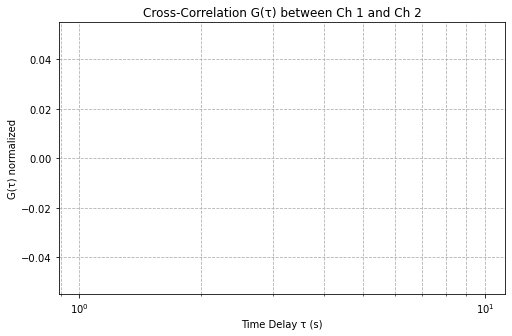

In [16]:
import ctypes as ct
from ctypes import byref
import time

# Constants
MODE_T2 = 2
TTREADMAX = 131072
FLAG_FIFOFULL = 0x0002
device_index = 0
acquisition_time_ms = 10000  # adjust this

# Load the DLL
hhlib = ct.WinDLL("hhlib.dll")

# Create buffers
buffer = (ct.c_uint * TTREADMAX)()
nRecords = ct.c_int()
flags = ct.c_int()
resolution = ct.c_double()

# Initialize device
serial = ct.create_string_buffer(b"", 8)
hhlib.HH_OpenDevice(device_index, serial)

hhlib.HH_Initialize(device_index, MODE_T2, 0)
hhlib.HH_Calibrate(device_index)
hhlib.HH_SetSyncDiv(device_index, 1)
hhlib.HH_SetSyncCFD(device_index, 50, 10)
hhlib.HH_SetSyncChannelOffset(device_index, 0)

# Configure input channels (assuming 2 channels)
for ch in range(2):
    hhlib.HH_SetInputCFD(device_index, ch, 50, 10)
    hhlib.HH_SetInputChannelOffset(device_index, ch, 5000)

hhlib.HH_GetResolution(device_index, byref(resolution))
print(f"Resolution: {resolution.value} ps")

# Start measurement
hhlib.HH_StartMeas(device_index, acquisition_time_ms)
time.sleep(acquisition_time_ms / 1000)

# Read data
hhlib.HH_GetFlags(device_index, byref(flags))
if flags.value & FLAG_FIFOFULL:
    print("FIFO overrun!")
else:
    retcode = hhlib.HH_ReadFiFo(device_index, buffer, TTREADMAX, byref(nRecords))
    print(f"Records read: {nRecords.value}")

    # Decode records (T2 Mode: 32-bit words)
    timestamps = []
    channels = []

    WRAPAROUND = 33554432
    oflcorrection = 0

    for i in range(nRecords.value):
        record = buffer[i]
        special = (record >> 31) & 1
        channel = (record >> 25) & 0x3F
        timeTag = record & 0x1FFFFFF

        if special:
            if channel == 0x3F:
                oflcorrection += WRAPAROUND * timeTag
            elif 1 <= channel <= 15:
                true_time = oflcorrection + timeTag
                # Marker
            elif channel == 0:
                true_time = oflcorrection + timeTag
                channels.append(0)
                timestamps.append(true_time * resolution.value * 1e-12)
        else:
            true_time = oflcorrection + timeTag
            channels.append(channel + 1)
            timestamps.append(true_time * resolution.value * 1e-12)

# Stop measurement
hhlib.HH_StopMeas(device_index)
hhlib.HH_CloseDevice(device_index)

import numpy as np
import matplotlib.pyplot as plt

def plot_cross_correlation(timestamps, channels, ch_a=1, ch_b=2,
                           bin_edges=None, max_delay=1e-4, min_delay=1e-7, bins=100):
    """
    Compute and plot cross-correlation G_AB(τ) from timestamped photon events.

    Parameters:
        timestamps: array of arrival times (in seconds)
        channels: array of channel numbers corresponding to timestamps
        ch_a: channel A (reference)
        ch_b: channel B (correlated with A)
        bin_edges: custom bin edges for histogram (optional)
        max_delay: maximum τ (seconds)
        min_delay: minimum τ (seconds)
        bins: number of histogram bins
    """

    # Filter A and B timestamps
    times_a = timestamps[channels == ch_a]
    times_b = timestamps[channels == ch_b]

    # Sort for efficient search
    times_b.sort()

    # Store time differences
    time_diffs = []

    for ta in times_a:
        # Find events in B within [ta + min_delay, ta + max_delay]
        t_min = ta + min_delay
        t_max = ta + max_delay
        idx_start = np.searchsorted(times_b, t_min, side='left')
        idx_end   = np.searchsorted(times_b, t_max, side='right')

        time_diffs.extend(times_b[idx_start:idx_end] - ta)

    time_diffs = np.array(time_diffs)

    # Histogram the time differences
    if bin_edges is None:
        bin_edges = np.logspace(np.log10(min_delay), np.log10(max_delay), bins)

    hist, edges = np.histogram(time_diffs, bins=bin_edges)

    # Normalize (optional, for G(t) interpretation)
    norm = hist / np.max(hist)

    # Plot
    plt.figure(figsize=(8, 5))
    plt.plot(edges[:-1], norm, lw=1, color='blue')
    plt.xscale('log')
    plt.xlabel("Time Delay τ (s)")
    plt.ylabel("G(τ) normalized")
    plt.title(f"Cross-Correlation G(τ) between Ch {ch_a} and Ch {ch_b}")
    plt.grid(True, which='both', ls='--')
    plt.show()

timestamps = np.array(timestamps)
channels = np.array(channels)

plot_cross_correlation(timestamps, channels, ch_a=1, ch_b=2)


<ipython-input-11-6fed01c287d2>:48: RuntimeWarning: invalid value encountered in divide
  norm = hist / np.max(hist)


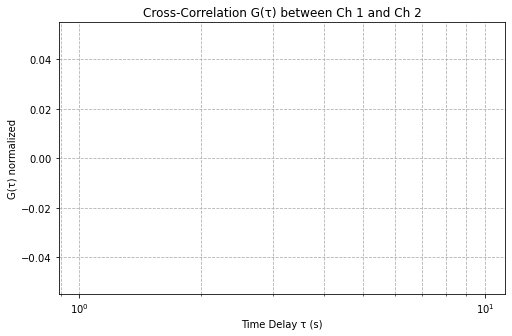